In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
np.random.seed(42)
plt.style.use('fivethirtyeight')
sns.set()
sns.set_context("talk")
%matplotlib inline

In [6]:
X = np.random.normal(70, 1, size=(50,1))
Y = np.random.normal(70,1,size=(50,1))

In [3]:
Y.shape

(50, 1)

In [7]:
from sklearn.preprocessing import MinMaxScaler


scaler = MinMaxScaler()
x_new = scaler.fit_transform(X)
y_new = scaler.fit_transform(Y)

ModuleNotFoundError: No module named 'sklearn'

In [43]:
print(min(X))
print(min(x_new))
print(max(X))
print(max(x_new))

print(min(Y))
print(min(y_new))
print(max(Y))
print(max(y_new))

[67.97485741]
[0.]
[73.85273149]
[1.]
[66.75873266]
[0.]
[72.13303337]
[1.]


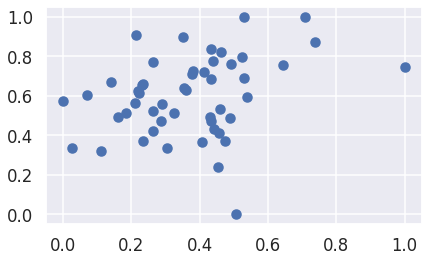

In [44]:
plt.scatter(x_new,y_new)

In [45]:
def h(theta0, theta1, x):
    return theta0 + theta1*x

In [46]:
def sq_error(x,y,theta0,theta1):
    
    L = lambda a : a ** 2
    y_pre = h(theta0, theta1, x)
    error_lst = y - y_pre
    return float(sum(L(error_lst))) / len(x)

In [47]:
sq_error(x_new, y_new, 0.4,0.5)

0.037294038099470884

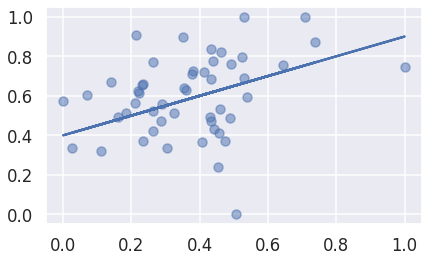

In [48]:
import pylab

y_pre = h(0.4,0.5,x_new)
pylab.plot(x_new,y_pre)
pylab.scatter(x_new, y_new, alpha=0.5)

In [49]:
sum_theta0 = lambda a,b : float(sum(b*x+a-y for x,y in zip(x_new,y_new)))
sum_theta1 = lambda a,b : float(sum((b*x+a-y)*x for x,y in zip(x_new,y_new)))

prev_theta0, prev_theta1 = 0,0
old_error = sq_error(x_new,y_new, prev_theta0, prev_theta1)
new_error = old_error + 100
alpha = 0.001
num_iters =0

while abs(new_error - old_error)>= 0.0001:
    theta0 = prev_theta0 - alpha * sum_theta0(prev_theta0, prev_theta1)
    theta1 = prev_theta1 - alpha * sum_theta1(prev_theta0, prev_theta1)
    
    new_error = sq_error(x_new, y_new, theta0, theta1)
    old_error = sq_error(x_new, y_new, prev_theta0, prev_theta1)
    
    prev_theta0 = theta0
    prev_theta1 = theta1
    
    num_iters += 1
    
    print(f'num_iters = {num_iters}, theta0 = {theta0}, theta1 = {theta1}')

num_iters = 1, theta0 = 0.02995822784317209, theta1 = 0.011640398308984645
num_iters = 2, theta0 = 0.058203068347789086, theta1 = 0.022626780479476517
num_iters = 3, theta0 = 0.08483229740348179, theta1 = 0.03299645115438171
num_iters = 4, theta0 = 0.10993811155744555, theta1 = 0.04278458630392208
num_iters = 5, theta0 = 0.13360744638551958, theta1 = 0.05202435469292564
num_iters = 6, theta0 = 0.15592227669622583, theta1 = 0.060747032416893214
num_iters = 7, theta0 = 0.17695989960442338, theta1 = 0.06898211090235416
num_iters = 8, theta0 = 0.1967932014520808, theta1 = 0.07675739874445499
num_iters = 9, theta0 = 0.21549090949788938, theta1 = 0.08409911773344349
num_iters = 10, theta0 = 0.23311782924484528, theta1 = 0.09103199340164451
num_iters = 11, theta0 = 0.24973506822533317, theta1 = 0.0975793404036016
num_iters = 12, theta0 = 0.26540024701648013, theta1 = 0.10376314302421669
num_iters = 13, theta0 = 0.28016769821445175, theta1 = 0.10960413109289664
num_iters = 14, theta0 = 0.29408

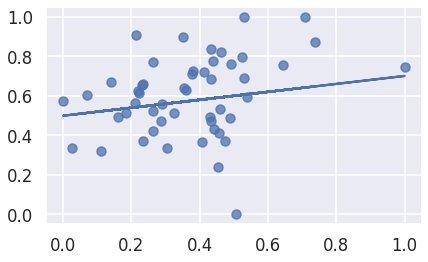

In [50]:
y_pre = h(theta0,theta1,x_new)
pylab.plot(x_new,y_pre)
pylab.scatter(x_new, y_new, alpha=0.75)